# 99.7d.1 Stiffness 1: Binding Kinetics

## Contents

**Tools:** CADET-Python, Binding-kinetics explorer; ipywidgets; a three-protein competitive Langmuir separation; integrator metrics.

**Python used:** Imports, working-directory and import-path setup, parameter assignment, helper calls and slider configuration.

**Introduces:** Joint scaling of adsorption and desorption rates, fixed equilibrium constants, kinetic and rapid-equilibrium binding, and the cost of fast modes.

1. The column, binding model and fixed spatial grid
2. Changing binding speed while preserving equilibrium
3. Comparing chromatograms, BDF steps and stiffness indicators
4. Interpreting the fast-binding limit and its limitations

How much does fast binding cost when equilibrium stays the same? We scale both binding rate constants together and compare the solution and integrator work over a wide range of rates.

## Stiffness 1 — Binding Kinetics

A three component protein separation on an ordinary lab column: 10 cm bed, 1 cm diameter, 150 cm/h, 45 µm resin, competitive Langmuir binding. The three proteins differ only in affinity and elute in order.

| | |
|---|---|
| bed length / diameter | 0.1 m / 0.01 m |
| superficial velocity | 4.2·10⁻⁴ m/s (150 cm/h) |
| bed / particle porosity | 0.37 / 0.75 |
| particle radius | 45 µm |
| axial dispersion | 10⁻⁷ m²/s (column Péclet ≈ 1100) |
| film diffusion | 10⁻⁵ m/s |
| binding capacity | 2 mol/m³, $K$ = 5 / 10 / 20 m³/mol |
| feed | 0.02 mol/m³ each, 60 s pulse |

The loading is deliberately moderate: $K c$ = 0.1 / 0.2 / 0.4, so the isotherm is **nonlinear but not overloaded**. There is no self-sharpening shock, and **25 finite volume cells** already resolve the chromatogram to better than 1 % of the feed concentration. That matters — it means anything we see below is the binding, and not a front being resolved.

In [ ]:
# This notebook lives one folder below the workshop root, while `utility`
# and everything under `data/` are addressed relative to that root.
# Step up into it before importing anything.
import os
import sys

root = os.path.abspath(os.curdir)
while not os.path.isdir(os.path.join(root, 'utility')):
    root, previous = os.path.dirname(root), root
    if root == previous:
        raise RuntimeError('no folder containing utility/ above this notebook')

os.chdir(root)
if root not in sys.path:
    sys.path.insert(0, root)

,process,rate / s^-1,set by,time scale / s
0,binding (Langmuir),1.400000,physics,0.714286
1,film mass transfer,1.135135,physics,0.880952
2,"convection, one grid node",0.283784,discretization,3.523810
3,"convection, whole column",0.011351,physics,88.095238
4,"axial dispersion, one grid node",0.006250,discretization,160.000000
5,"axial dispersion, whole column",0.000010,physics,100000.000000


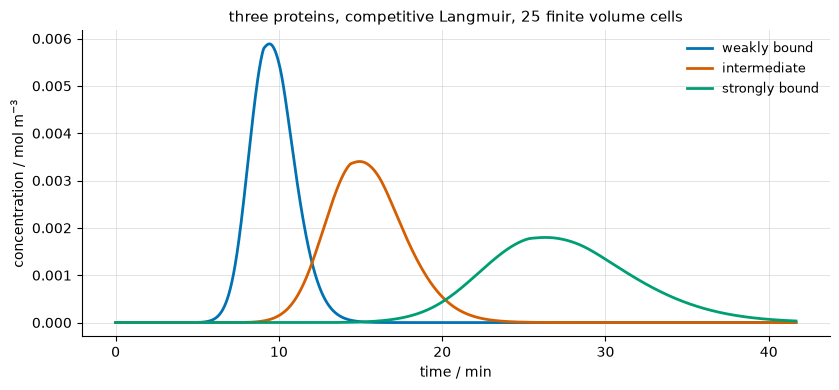

In [1]:
import utility.binding_kinetics_explorer as explorer

CELLS = 25      # enough for 1 % of the feed peak, and no more

explorer.show_setting(n_elements=CELLS)

## What this notebook does

The binding rate constants are scaled **jointly**, $k_a$ and $k_d$ together, so $K = k_a/k_d$ and therefore the isotherm and the equilibrium chromatogram never change. Only the speed of the binding moves — over **twenty decades**, ending one step beyond the fast limit at `IS_KINETIC = 0`.

Everything else is held fixed: same grid, same tolerances, same column. So the question is as clean as it gets in a chromatography model:

> **what does a fast process cost an implicit integrator, when it is the only thing changing?**

The slider runs each setting and records the binding rate, the number of BDF steps, and the stiffness indicator — the binding rate divided by the rate of the **slowest** other process in the model. Move it and watch the two columns.

In [2]:
from ipywidgets import interact, widgets

# start, end and step choose which decades of the binding rate the slider
# offers; n_elements fixes the grid used for every run.
show_kinetics = explorer.make_explorer(n_elements=CELLS,
                                       start=-6, end=14, step=1)

interact(show_kinetics,
         kinetics=widgets.SelectionSlider(
             options=show_kinetics.options,
             value=show_kinetics.default,
             description="kinetics",
             continuous_update=False,
         ));

interactive(children=(SelectionSlider(continuous_update=False, description='kinetics', index=6, options=(('1e-…

## What happened

**Nothing.** Between binding rates of $1.4\,\mathrm{s^{-1}}$ and $1.4\cdot10^{14}\,\mathrm{s^{-1}}$ the integrator takes 1646 and 1668 steps — **1.3 % apart** — at an unchanged mean BDF order of 5. Over that span the stiffness indicator climbs from about $10^{5}$ to $10^{19}$. Beyond factor $10^{6}$ the step count is not merely similar but *identical*, 1668 every time, and rapid equilibrium lands on 1668 as well.

The small variation that does exist sits at the **slow** end, where the chromatogram is still changing shape: at a binding rate of $10^{-6}\,\mathrm{s^{-1}}$ nothing is retained and the pulse passes straight through, and as the binding speeds up the three peaks appear and separate. That costs steps because the *solution* became richer, not because the system became stiffer.

### Why

The binding contributes a **real, negative, strongly damped** eigenvalue: $\mathrm{d}q/\mathrm{d}t = -(k_a c + k_d)(q - q_\mathrm{eq})$. BDF is unconditionally stable for exactly that kind of mode at any step size. Once its transient has decayed — within microseconds here — the fast component is slaved to the slow dynamics and contributes nothing the error control can see. Making it a thousand times faster makes it decay a thousand times sooner.

This is the implicit method doing the job it was chosen for. Section 4.2 measured what the same separation of scales costs a method that has *not* mitigated it: explicit Euler needed 5000 steps where implicit needed 50.

### What this does **not** say

- **Not** that stiffness never costs. It says that *this* source, in isolation, does not. In the overloaded two-component benchmark, speeding up the same kind of binding did cost — but the cost was the **shock** that fast binding reveals, not the fast mode itself. A fast process bills you for whatever solution feature it uncovers; here the equilibrium limit is smooth, so there is nothing to uncover.
- **Not** that fast rate constants are always safe to configure. The rate being harmless does not make the *numbers* harmless: see the `Fail case 908` notebook, where $k_d = 5.6\cdot10^{7}$ combined with $\nu \approx 10$ produced residual terms of order $10^{33}$ that had to cancel to machine precision, and the simulation failed at the first step.
- **Not** a general law. One case, one binding model, one transport model. The mechanism generalises; the numbers do not.

> **Take-away.** A fast, well-damped physical process is close to free in CADET. If your simulation is slow, look at what your solution looks like and how finely you are discretizing it, before you look at your rate constants.

## Summary

- Scaling adsorption and desorption rates together preserves their equilibrium ratio.
- In this smooth separation, making binding faster beyond the equilibrium limit changes the step count very little.

**Next lesson:** [**99.7d.2 Stiffness 2: Spatial Discretization**](<99.7d.2_stiffness2_spatial_discretization.ipynb>) varies DG degree and tolerance at fixed system size.